Notebook 2: Exploratory data analysis

Load processed data

In [3]:
%pip install matplotlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "processed_data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(
    PROCESSED_DIR / "train_utterances.csv"
)

validation_df = pd.read_csv(
    PROCESSED_DIR / "validation_utterances.csv"
)

test_df = pd.read_csv(
    PROCESSED_DIR / "test_utterances.csv"
)


  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Dataset summary

In [4]:
def split_summary(dataframe, split_name):
    dialogue_sizes = dataframe.groupby(
        "dialogue_id"
    ).size()

    return {
        "split": split_name,
        "dialogues": dataframe[
            "dialogue_id"
        ].nunique(),
        "utterances": len(dataframe),
        "mean_dialogue_length": (
            dialogue_sizes.mean()
        ),
        "median_dialogue_length": (
            dialogue_sizes.median()
        ),
        "mean_utterance_words": dataframe[
            "utterance_length_words"
        ].mean(),
        "median_utterance_words": dataframe[
            "utterance_length_words"
        ].median()
    }


dataset_summary = pd.DataFrame([
    split_summary(train_df, "train"),
    split_summary(validation_df, "validation"),
    split_summary(test_df, "test")
])

display(dataset_summary.round(2))

dataset_summary.to_csv(
    TABLES_DIR / "dataset_summary.csv",
    index=False
)

,split,dialogues,utterances,mean_dialogue_length,median_dialogue_length,mean_utterance_words,median_utterance_words
0,train,11118,87170,7.84,7.0,13.61,11.0
1,validation,1000,8069,8.07,8.0,13.50,11.0
2,test,1000,7740,7.74,7.0,13.78,11.0


Emotion Distribution

In [5]:
emotion_distribution = (
    train_df["emotion_name"]
    .value_counts()
    .rename_axis("emotion")
    .reset_index(name="count")
)

emotion_distribution["percentage"] = (
    emotion_distribution["count"]
    / emotion_distribution["count"].sum()
    * 100
)

display(emotion_distribution.round(2))

,emotion,count,percentage
0,neutral,72143,82.76
1,happiness,11182,12.83
2,surprise,1600,1.84
3,sadness,969,1.11
4,anger,827,0.95
5,disgust,303,0.35
6,fear,146,0.17


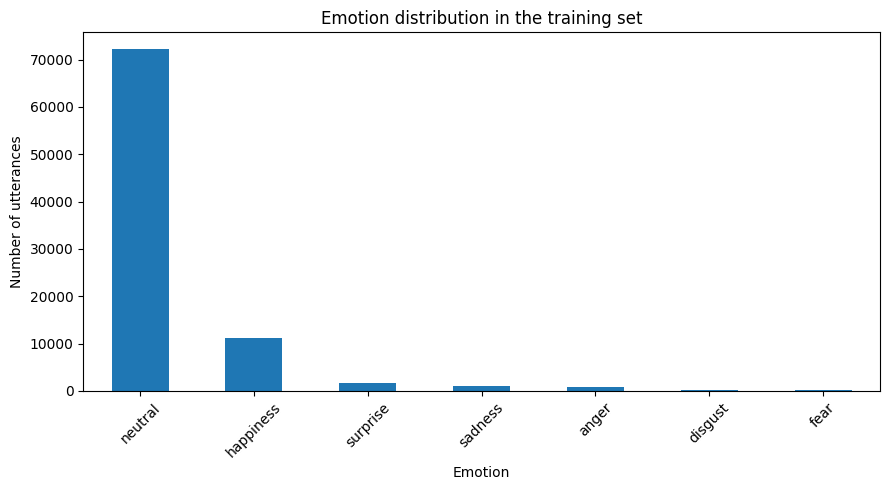

In [6]:
plt.figure(figsize=(9, 5))

train_df["emotion_name"].value_counts().plot(
    kind="bar"
)

plt.title("Emotion distribution in the training set")
plt.xlabel("Emotion")
plt.ylabel("Number of utterances")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "emotion_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Distribution across splits 

In [7]:
combined_df = pd.concat(
    [
        train_df.assign(dataset_split="train"),
        validation_df.assign(
            dataset_split="validation"
        ),
        test_df.assign(dataset_split="test")
    ],
    ignore_index=True
)

split_class_distribution = (
    pd.crosstab(
        combined_df["emotion_name"],
        combined_df["dataset_split"],
        normalize="columns"
    )
    * 100
)

display(split_class_distribution.round(2))

dataset_split,test,train,validation
emotion_name,,,
anger,1.52,0.95,0.95
disgust,0.61,0.35,0.04
fear,0.22,0.17,0.14
happiness,13.17,12.83,8.48
neutral,81.67,82.76,88.09
sadness,1.32,1.11,0.98
surprise,1.50,1.84,1.33


Utterance Length

In [8]:
display(
    train_df["utterance_length_words"].describe()
)

count    87170.000000
mean        13.606126
std         10.316376
min          1.000000
25%          7.000000
50%         11.000000
75%         17.000000
max        278.000000
Name: utterance_length_words, dtype: float64

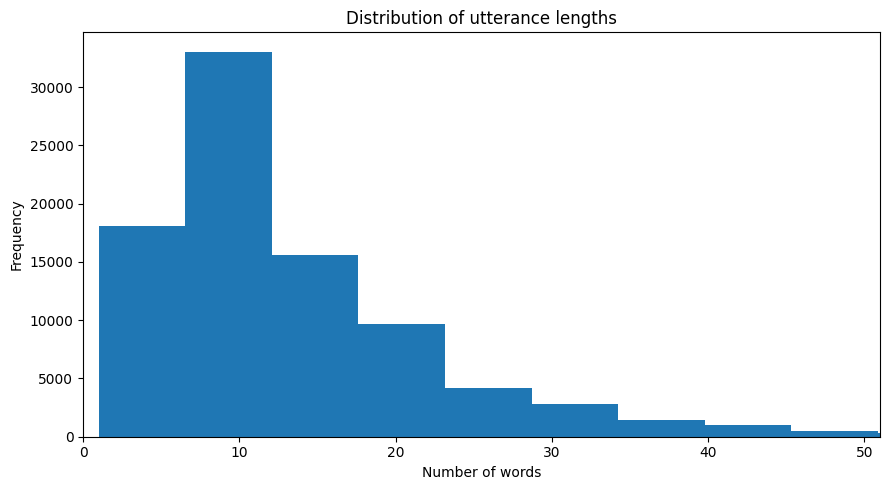

In [9]:
upper_limit = train_df[
    "utterance_length_words"
].quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    train_df["utterance_length_words"],
    bins=50
)

plt.xlim(0, upper_limit)
plt.title("Distribution of utterance lengths")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "utterance_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Length by emotion

In [10]:
length_by_emotion = (
    train_df
    .groupby("emotion_name")[
        "utterance_length_words"
    ]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)

display(length_by_emotion.round(2))

,count,mean,median,std
emotion_name,,,,
fear,146,17.60,13.0,14.21
anger,827,17.43,14.0,14.70
disgust,303,15.74,13.0,11.03
sadness,969,14.71,12.0,10.03
neutral,72143,13.75,11.0,10.47
happiness,11182,12.45,10.0,8.91
surprise,1600,11.73,10.0,7.81


Dialogue-length distribution

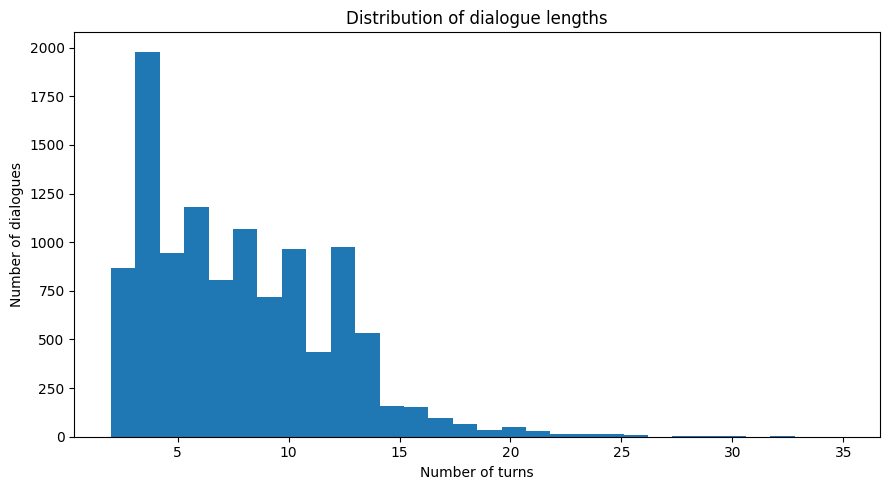

In [11]:
dialogue_lengths = (
    train_df.groupby("dialogue_id")
    .size()
)

plt.figure(figsize=(9, 5))

plt.hist(dialogue_lengths, bins=30)

plt.title("Distribution of dialogue lengths")
plt.xlabel("Number of turns")
plt.ylabel("Number of dialogues")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dialogue_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Emotion transition matrix

In [12]:
transition_records = []

for _, group in train_df.groupby("dialogue_id"):
    group = group.sort_values("turn_index")
    emotions = group["emotion_name"].tolist()

    for previous_emotion, current_emotion in zip(
        emotions[:-1],
        emotions[1:]
    ):
        transition_records.append({
            "previous_emotion": previous_emotion,
            "current_emotion": current_emotion
        })

transition_df = pd.DataFrame(
    transition_records
)

transition_matrix = pd.crosstab(
    transition_df["previous_emotion"],
    transition_df["current_emotion"],
    normalize="index"
)

display(transition_matrix.round(3))

current_emotion,anger,disgust,fear,happiness,neutral,sadness,surprise
previous_emotion,,,,,,,
anger,0.119,0.004,0.001,0.009,0.792,0.052,0.023
disgust,0.020,0.133,0.000,0.020,0.781,0.008,0.039
fear,0.000,0.000,0.031,0.053,0.863,0.000,0.053
happiness,0.000,0.001,0.001,0.644,0.334,0.002,0.018
neutral,0.009,0.003,0.002,0.074,0.882,0.012,0.019
sadness,0.036,0.001,0.001,0.043,0.815,0.066,0.036
surprise,0.014,0.008,0.003,0.110,0.815,0.011,0.038


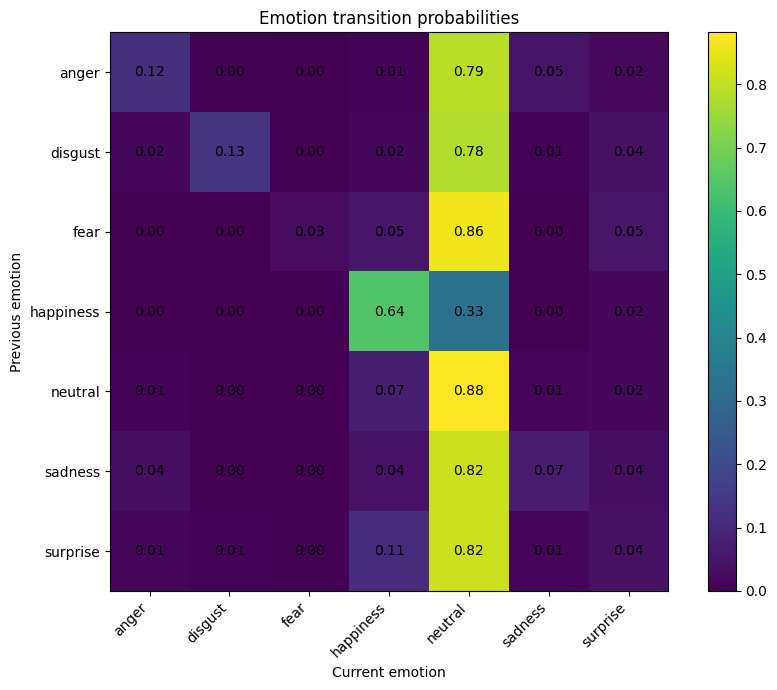

In [13]:
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    transition_matrix.values
)

ax.set_xticks(
    range(len(transition_matrix.columns))
)

ax.set_xticklabels(
    transition_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(transition_matrix.index))
)

ax.set_yticklabels(
    transition_matrix.index
)

for row in range(
    transition_matrix.shape[0]
):
    for column in range(
        transition_matrix.shape[1]
    ):
        ax.text(
            column,
            row,
            f"{transition_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title("Emotion transition probabilities")
ax.set_xlabel("Current emotion")
ax.set_ylabel("Previous emotion")

fig.colorbar(image)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "emotion_transition_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()